# Câncer de mama — modelagem e avaliação

Este notebook acompanha as etapas do projeto até o **treinamento e a avaliação** dos classificadores: exploração e preparação dos dados, separação treino/validação/teste, comparação por validação cruzada, avaliação final e análises de importância/SHAP.

São usados os mesmos modelos do projeto: Regressão Logística, SVM com probabilidades calibradas e Árvore de Decisão. A divisão é estratificada em aproximadamente 70% para treino, 15% para validação e 15% para teste. O teste fica separado da seleção do modelo.

**Não há exportação do modelo neste notebook.** A última etapa é a avaliação e interpretação dos resultados.

> **Aviso:** este trabalho é acadêmico. As estimativas não substituem exames, diagnóstico ou avaliação de profissionais de saúde.


In [4]:
%pip -q install ipython numpy pandas scikit-learn matplotlib seaborn shap


In [5]:
from pathlib import Path
import io
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TARGET = "diagnosis"
ID_COLUMN = "id"
RESULTS_DIR = Path("results")
GRAPHICS_DIR = RESULTS_DIR / "graphics"
METRICS_DIR = RESULTS_DIR / "metrics"
GRAPHICS_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")


## 1. Carregamento e exploração dos dados

O notebook procura `data/breast_cancer.csv` na pasta atual. Se o arquivo não estiver disponível e o notebook estiver no Google Colab, será solicitado o upload do CSV.


In [6]:
dataset_candidates = [
    Path("data/breast_cancer.csv"),
    Path("../data/breast_cancer.csv"),
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)

if dataset_path is not None:
    df_original = pd.read_csv(dataset_path)
    print(f"Base carregada de: {dataset_path.resolve()}")
else:
    try:
        from google.colab import files
    except ImportError as error:
        raise FileNotFoundError(
            "Coloque o CSV em data/breast_cancer.csv ou execute no Colab e envie o arquivo."
        ) from error
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError("Envie um arquivo CSV para continuar.")
    selected_name = "breast_cancer.csv" if "breast_cancer.csv" in csv_names else csv_names[0]
    df_original = pd.read_csv(io.BytesIO(uploaded[selected_name]))
    print(f"Base carregada do arquivo enviado: {selected_name}")

if TARGET not in df_original.columns:
    raise ValueError(f"A base precisa conter a coluna '{TARGET}'.")

print(f"Dimensões: {df_original.shape[0]} linhas x {df_original.shape[1]} colunas")
display(df_original.head())


Base carregada de: /content/data/breast_cancer.csv
Dimensões: 569 linhas x 33 colunas


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Tipos de dados e valores preenchidos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    f

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Valores ausentes por coluna:


,ausentes
Unnamed: 32,569
id,0
diagnosis,0
texture_mean,0
radius_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
perimeter_mean,0
concave points_mean,0


Linhas duplicadas: 0
IDs duplicados: 0

Distribuição dos diagnósticos:


,quantidade
diagnosis,
B,357
M,212


,percentual (%)
diagnosis,
B,62.741652
M,37.258348


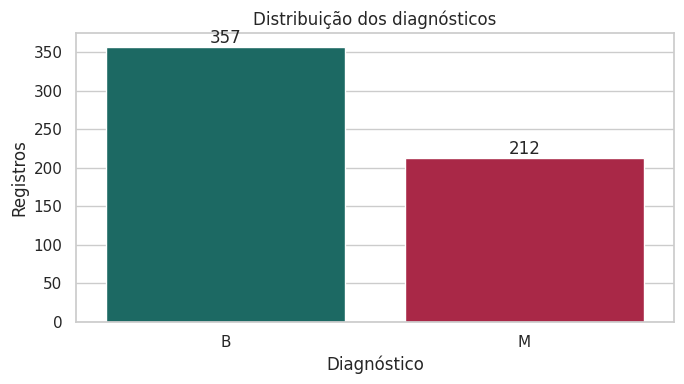

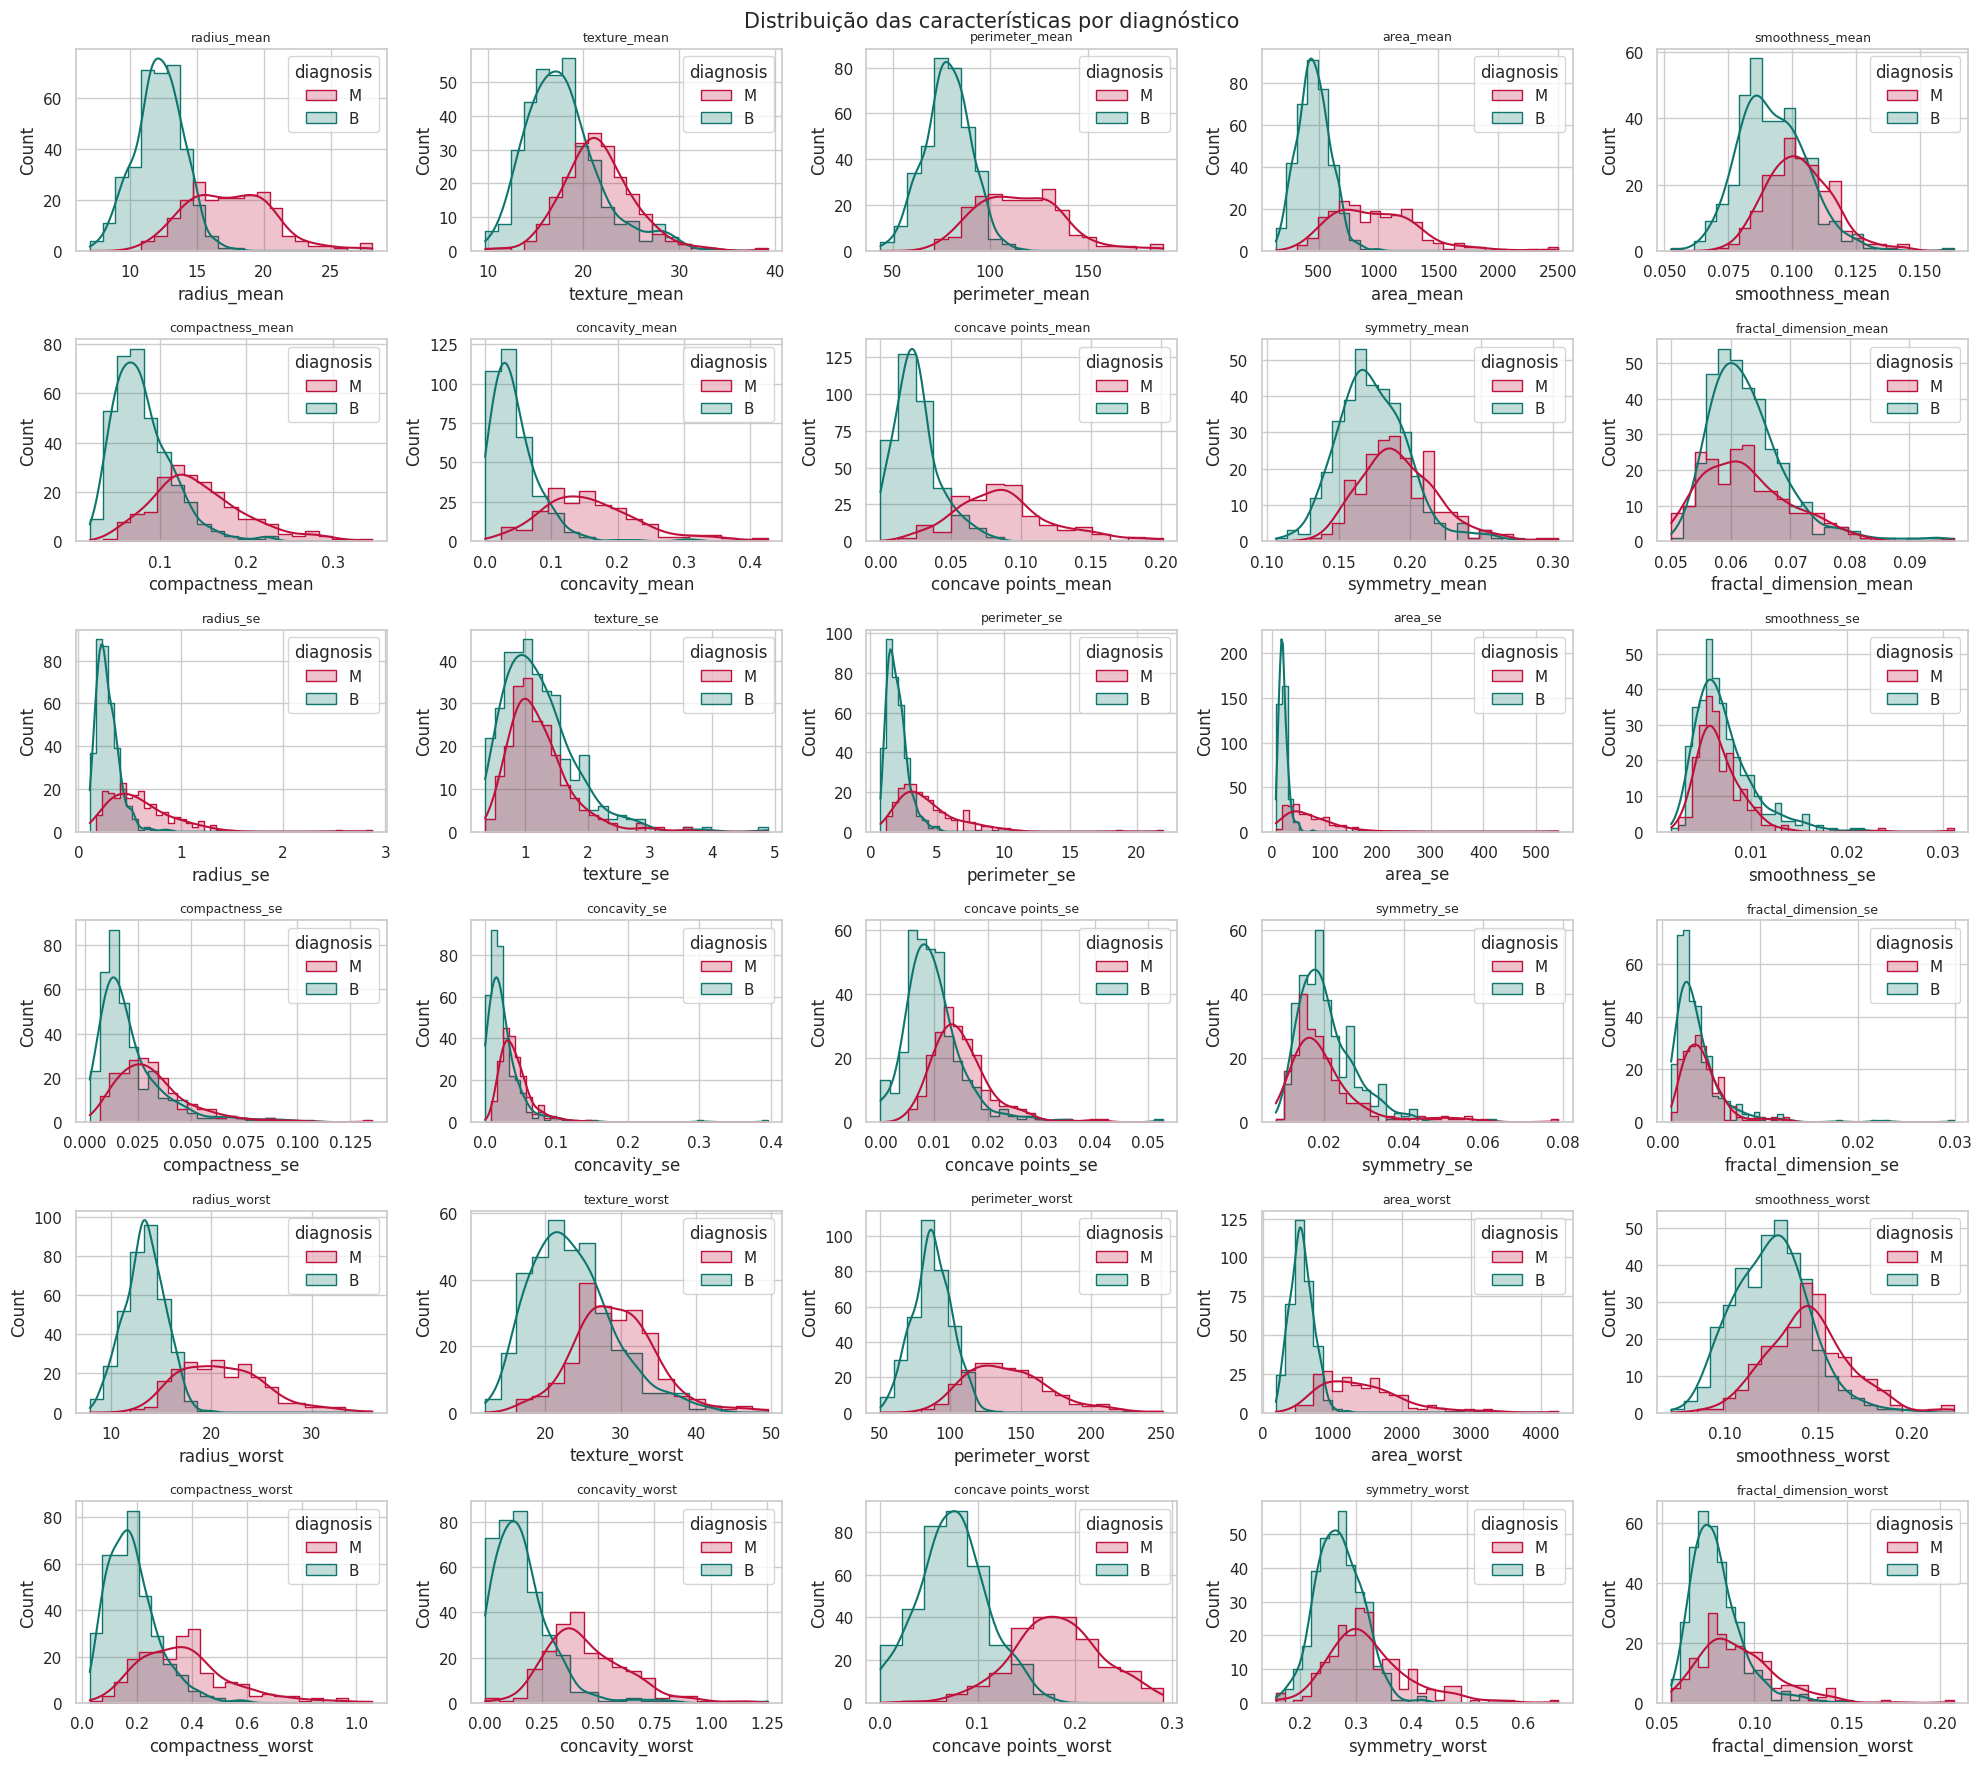

In [7]:
print("Tipos de dados e valores preenchidos:")
df_original.info()

print("\nEstatísticas descritivas:")
display(df_original.drop(columns=[ID_COLUMN], errors="ignore").describe().T)

print("\nValores ausentes por coluna:")
display(df_original.isna().sum().sort_values(ascending=False).to_frame("ausentes"))
print(f"Linhas duplicadas: {df_original.duplicated().sum()}")
if ID_COLUMN in df_original.columns:
    print(f"IDs duplicados: {df_original[ID_COLUMN].duplicated().sum()}")

print("\nDistribuição dos diagnósticos:")
display(df_original[TARGET].value_counts(dropna=False).to_frame("quantidade"))
display(
    (df_original[TARGET].value_counts(normalize=True, dropna=False) * 100)
    .rename("percentual (%)")
    .to_frame()
)
df_original.drop(columns=[ID_COLUMN], errors="ignore").describe().to_csv(
    RESULTS_DIR / "estatisticas_descritivas.csv"
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=df_original,
    x=TARGET,
    hue=TARGET,
    order=["B", "M"],
    palette={"B": "#0f766e", "M": "#be123c"},
    legend=False,
    ax=ax,
)
ax.set(title="Distribuição dos diagnósticos", xlabel="Diagnóstico", ylabel="Registros")
for container in ax.containers:
    ax.bar_label(container)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "distribuicao_diagnosticos.png", dpi=200)
plt.show()

feature_columns_original = [
    column for column in df_original.columns if column not in (TARGET, ID_COLUMN)
]
numeric_features = [
    column for column in df_original[feature_columns_original].select_dtypes(include=np.number)
    if df_original[column].notna().any()
]
ncols = 5
nrows = max(1, int(np.ceil(len(numeric_features) / ncols)))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, max(4, nrows * 3)))
axes = np.asarray(axes).reshape(-1)
for ax, column in zip(axes, numeric_features):
    sns.histplot(
        data=df_original,
        x=column,
        hue=TARGET,
        palette={"B": "#0f766e", "M": "#be123c"},
        element="step",
        kde=True,
        ax=ax,
    )
    ax.set_title(column, fontsize=9)
for ax in axes[len(numeric_features):]:
    fig.delaxes(ax)
fig.suptitle("Distribuição das características por diagnóstico", fontsize=15)
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "distribuicao_caracteristicas.png", dpi=200, bbox_inches="tight")
plt.show()


## 2. Limpeza e pré-processamento

A coluna vazia é removida, o identificador `id` não entra no modelo e o alvo é convertido para números (`B = 0`, `M = 1`). Valores ausentes nas características são tratados dentro dos pipelines, que aprendem a mediana apenas nos dados usados para treinamento.


Dados preparados: 569 registros e 30 características.
Mapeamento do alvo: benigno = 0; maligno = 1.
Valores ausentes nas características: 0


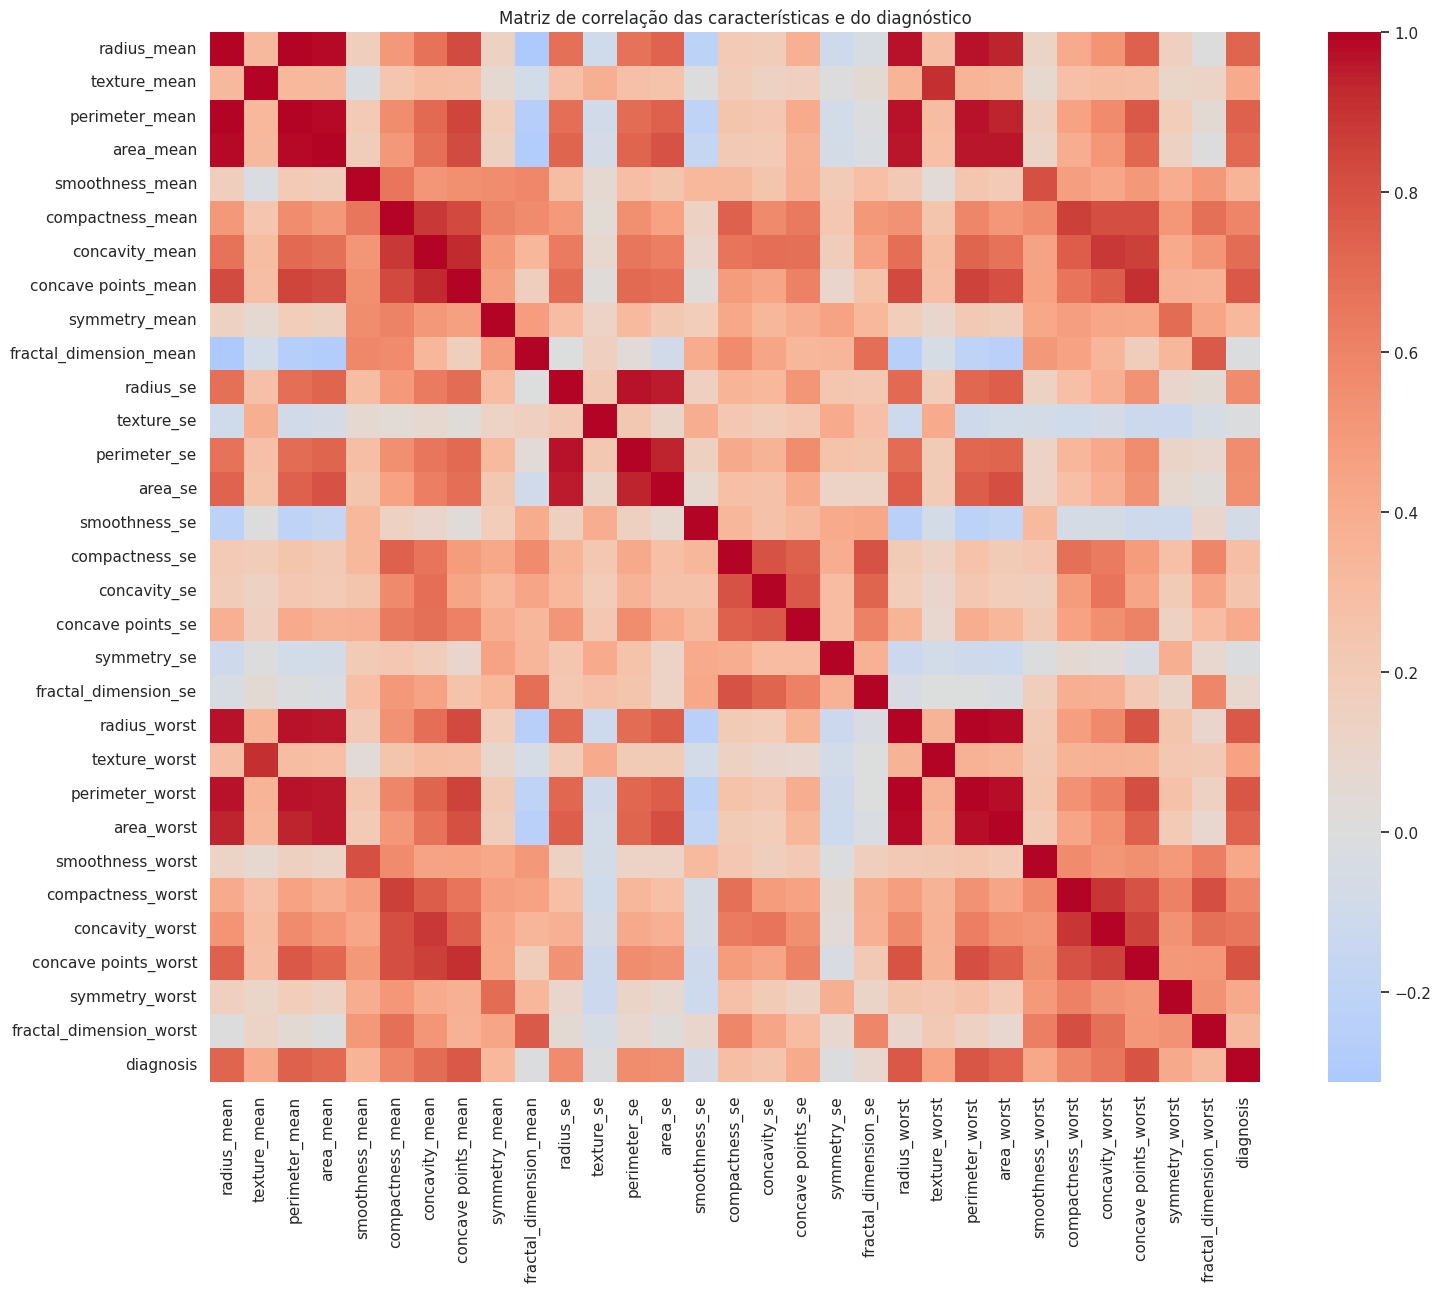

In [8]:
df = df_original.dropna(axis=1, how="all").copy()
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(str).str.strip().str.upper()
df[TARGET] = df[TARGET].map({"B": 0, "M": 1})

if df[TARGET].isna().any():
    raise ValueError("A coluna diagnosis deve conter somente os valores B e M.")

X = df.drop(columns=[TARGET, ID_COLUMN], errors="ignore").copy()
y = df[TARGET].astype(int)
X = X.apply(pd.to_numeric, errors="raise")
if X.empty:
    raise ValueError("Nenhuma característica foi encontrada para treinar os modelos.")

print(f"Dados preparados: {len(X)} registros e {X.shape[1]} características.")
print("Mapeamento do alvo: benigno = 0; maligno = 1.")
print(f"Valores ausentes nas características: {int(X.isna().sum().sum())}")

correlation = X.assign(diagnosis=y).corr(numeric_only=True)
correlation.to_csv(GRAPHICS_DIR / "matriz_correlacao.csv")
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(correlation, cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Matriz de correlação das características e do diagnóstico")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "matriz_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()


## 3. Separação em treino, validação e teste

A divisão é estratificada para manter proporções semelhantes de casos benignos e malignos. A validação cruzada será aplicada aos conjuntos de treino e validação (85% dos dados). O teste (15%) permanece separado para a avaliação final.


In [9]:
TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

X_train_validation, X_test, y_train_validation, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)
validation_fraction = VALIDATION_SIZE / (1 - TEST_SIZE)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_validation,
    y_train_validation,
    test_size=validation_fraction,
    random_state=RANDOM_STATE,
    stratify=y_train_validation,
)

print(f"Treino: {len(X_train)} registros ({len(X_train) / len(X):.1%})")
print(f"Validação: {len(X_validation)} registros ({len(X_validation) / len(X):.1%})")
print(f"Teste: {len(X_test)} registros ({len(X_test) / len(X):.1%})")


Treino: 397 registros (69.8%)
Validação: 86 registros (15.1%)
Teste: 86 registros (15.1%)


## 4. Definição dos modelos

São comparados três classificadores. Regressão Logística e SVM usam padronização; o SVM tem calibração interna para oferecer probabilidades estimadas. A Árvore de Decisão não precisa de padronização.


In [10]:
models = {
    "Regressão Logística": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        ]
    ),
    "SVM": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "classifier",
                CalibratedClassifierCV(
                    estimator=SVC(kernel="rbf", random_state=RANDOM_STATE),
                    method="sigmoid",
                    cv=5,
                    ensemble=False,
                ),
            ),
        ]
    ),
    "Árvore de Decisão": Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
        ]
    ),
}
print("Modelos:", ", ".join(models))


Modelos: Regressão Logística, SVM, Árvore de Decisão


## 5. Validação cruzada e seleção do modelo

Uma validação cruzada estratificada de cinco partes compara os modelos nos 85% de desenvolvimento. As previsões *out-of-fold* juntam previsões feitas por modelos que não treinaram nos respectivos registros. O limiar é escolhido pelo F2-score, que dá mais peso ao recall maligno. O teste não participa dessa escolha.


In [11]:
POSITIVE_CLASS = 1
RECALL_BETA = 2
X_development = pd.concat([X_train, X_validation], ignore_index=True)
y_development = pd.concat([y_train, y_validation], ignore_index=True)
cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def calculate_metrics(y_true, predictions):
    return {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, pos_label=POSITIVE_CLASS, zero_division=0),
        "recall": recall_score(y_true, predictions, pos_label=POSITIVE_CLASS, zero_division=0),
        "f1_score": f1_score(y_true, predictions, pos_label=POSITIVE_CLASS, zero_division=0),
    }


def find_recall_focused_threshold(scores, labels):
    best_threshold = None
    best_predictions = None
    best_rank = None
    for threshold in np.unique(scores):
        predictions = (scores >= threshold).astype(int)
        metrics = calculate_metrics(labels, predictions)
        rank = (
            fbeta_score(labels, predictions, beta=RECALL_BETA, pos_label=POSITIVE_CLASS, zero_division=0),
            metrics["recall"],
            metrics["precision"],
            metrics["f1_score"],
            threshold,
        )
        if best_rank is None or rank > best_rank:
            best_threshold = threshold
            best_predictions = predictions
            best_rank = rank
    return best_threshold, best_predictions


cv_rows = []
for name, model in models.items():
    fold_rows = []
    oof_scores = np.empty(len(X_development))

    for train_indices, validation_indices in cross_validator.split(X_development, y_development):
        fold_model = clone(model)
        X_fold_train = X_development.iloc[train_indices]
        y_fold_train = y_development.iloc[train_indices]
        X_fold_validation = X_development.iloc[validation_indices]
        y_fold_validation = y_development.iloc[validation_indices]

        fold_model.fit(X_fold_train, y_fold_train)
        fold_predictions = fold_model.predict(X_fold_validation)
        fold_rows.append(calculate_metrics(y_fold_validation, fold_predictions))
        oof_scores[validation_indices] = fold_model.predict_proba(X_fold_validation)[:, 1]

    fold_frame = pd.DataFrame(fold_rows)
    row = {
        f"{metric}_mean": fold_frame[metric].mean()
        for metric in ("accuracy", "precision", "recall", "f1_score")
    }
    row.update({
        f"{metric}_std": fold_frame[metric].std(ddof=0)
        for metric in ("accuracy", "precision", "recall", "f1_score")
    })
    threshold, oof_predictions = find_recall_focused_threshold(oof_scores, y_development)
    row.update({f"oof_{metric}": value for metric, value in calculate_metrics(y_development, oof_predictions).items()})
    row["oof_f2_score"] = fbeta_score(
        y_development, oof_predictions, beta=RECALL_BETA, pos_label=POSITIVE_CLASS, zero_division=0
    )
    row["model"] = name
    row["threshold"] = threshold
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["oof_f2_score", "oof_recall", "oof_precision", "oof_f1_score"],
    ascending=False,
).reset_index(drop=True)
cv_results.to_csv(METRICS_DIR / "comparacao_modelos_validacao_cruzada.csv", index=False)
display(cv_results)


,accuracy_mean,precision_mean,recall_mean,f1_score_mean,accuracy_std,precision_std,recall_std,f1_score_std,oof_accuracy,oof_precision,oof_recall,oof_f1_score,oof_f2_score,model,threshold
0,0.964841,0.951265,0.955556,0.952853,0.021312,0.034545,0.037680,0.028596,0.950311,0.893939,0.983333,0.936508,0.964052,SVM,0.162545
1,0.971048,0.982521,0.938889,0.959825,0.022063,0.023448,0.044444,0.030727,0.962733,0.935484,0.966667,0.950820,0.960265,Regressão Logística,0.307800
2,0.911061,0.880489,0.883333,0.881303,0.019954,0.045449,0.020787,0.025827,0.910973,0.878453,0.883333,0.880886,0.882353,Árvore de Decisão,1.000000


## 6. Treinamento final e avaliação no teste

O modelo mais bem classificado pela validação cruzada é ajustado com todos os dados de desenvolvimento (treino + validação). Em seguida, as métricas finais são calculadas no teste separado, usando o limiar selecionado sem consultar esse conjunto.


Modelo selecionado: SVM
Limiar selecionado pelo F2-score: 0.1625

Métricas no teste:


,accuracy,precision,recall,f1_score,threshold
model,,,,,
SVM,0.953488,0.888889,1.0,0.941176,0.162545



Relatório por classe (1 = maligno):
              precision    recall  f1-score   support

     Benigno       1.00      0.93      0.96        54
     Maligno       0.89      1.00      0.94        32

    accuracy                           0.95        86
   macro avg       0.94      0.96      0.95        86
weighted avg       0.96      0.95      0.95        86



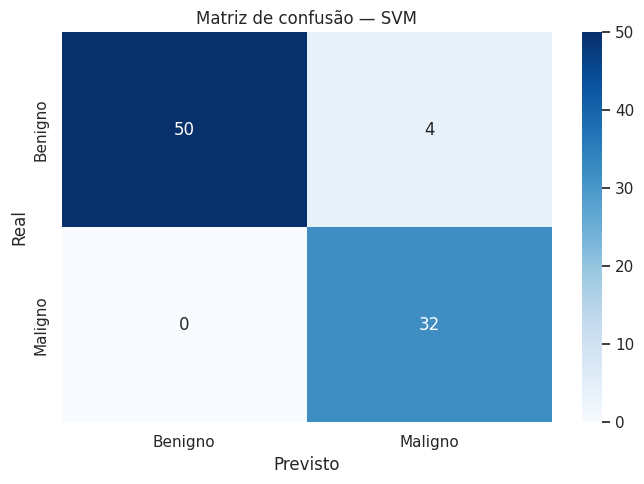

In [12]:
best_result = cv_results.iloc[0]
selected_model_name = best_result["model"]
selected_threshold = float(best_result["threshold"])
final_model = clone(models[selected_model_name])
final_model.fit(X_development, y_development)

test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int)
test_metrics = calculate_metrics(y_test, test_predictions)
test_metrics["model"] = selected_model_name
test_metrics["threshold"] = selected_threshold

print(f"Modelo selecionado: {selected_model_name}")
print(f"Limiar selecionado pelo F{RECALL_BETA}-score: {selected_threshold:.4f}")
print("\nMétricas no teste:")
display(pd.DataFrame([test_metrics]).set_index("model"))
print("\nRelatório por classe (1 = maligno):")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Benigno", "Maligno"],
    zero_division=0,
))

pd.DataFrame([test_metrics]).to_csv(METRICS_DIR / "metricas_teste.csv", index=False)
confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benigno", "Maligno"],
    yticklabels=["Benigno", "Maligno"],
    ax=ax,
)
ax.set(title=f"Matriz de confusão — {selected_model_name}", xlabel="Previsto", ylabel="Real")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "matriz_confusao_teste.png", dpi=200, bbox_inches="tight")
plt.show()


## 7. Importância por permutação e SHAP

A importância por permutação estima quanto embaralhar uma característica reduz o recall maligno. O SHAP apresenta contribuições das características para os scores do modelo. São análises complementares, não demonstram causalidade nem importância clínica.


,feature,importance,std
21,texture_worst,0.003125,0.009375
0,radius_mean,0.000000,0.000000
2,perimeter_mean,0.000000,0.000000
3,area_mean,0.000000,0.000000
4,smoothness_mean,0.000000,0.000000
1,texture_mean,0.000000,0.000000
6,concavity_mean,0.000000,0.000000
7,concave points_mean,0.000000,0.000000
8,symmetry_mean,0.000000,0.000000
9,fractal_dimension_mean,0.000000,0.000000


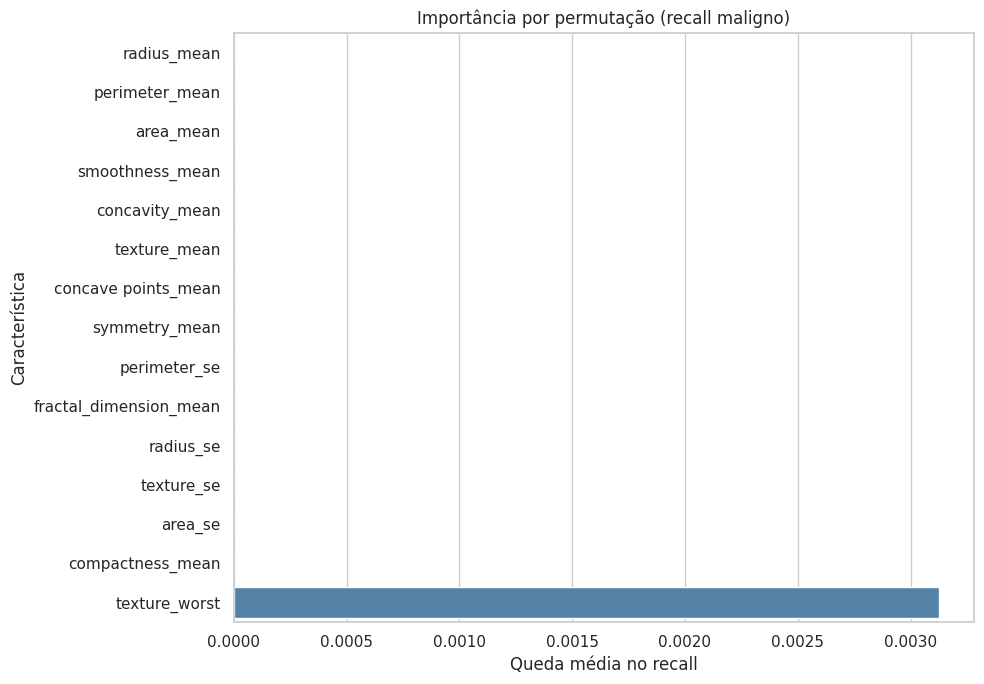

In [13]:
def recall_at_selected_threshold(estimator, features, labels):
    probabilities = estimator.predict_proba(features)[:, 1]
    predictions = (probabilities >= selected_threshold).astype(int)
    return recall_score(labels, predictions, pos_label=POSITIVE_CLASS, zero_division=0)


importance = permutation_importance(
    final_model,
    X_validation,
    y_validation,
    scoring=recall_at_selected_threshold,
    n_repeats=10,
    random_state=RANDOM_STATE,
)
importance_frame = pd.DataFrame({
    "feature": X.columns,
    "importance": importance.importances_mean,
    "std": importance.importances_std,
}).sort_values("importance", ascending=False)
importance_frame.to_csv(METRICS_DIR / "importancia_caracteristicas.csv", index=False)
display(importance_frame.head(10))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(
    data=importance_frame.head(15).sort_values("importance"),
    x="importance",
    y="feature",
    color="steelblue",
    ax=ax,
)
ax.set(title="Importância por permutação (recall maligno)", xlabel="Queda média no recall", ylabel="Característica")
fig.tight_layout()
fig.savefig(GRAPHICS_DIR / "importancia_caracteristicas.png", dpi=200, bbox_inches="tight")
plt.show()


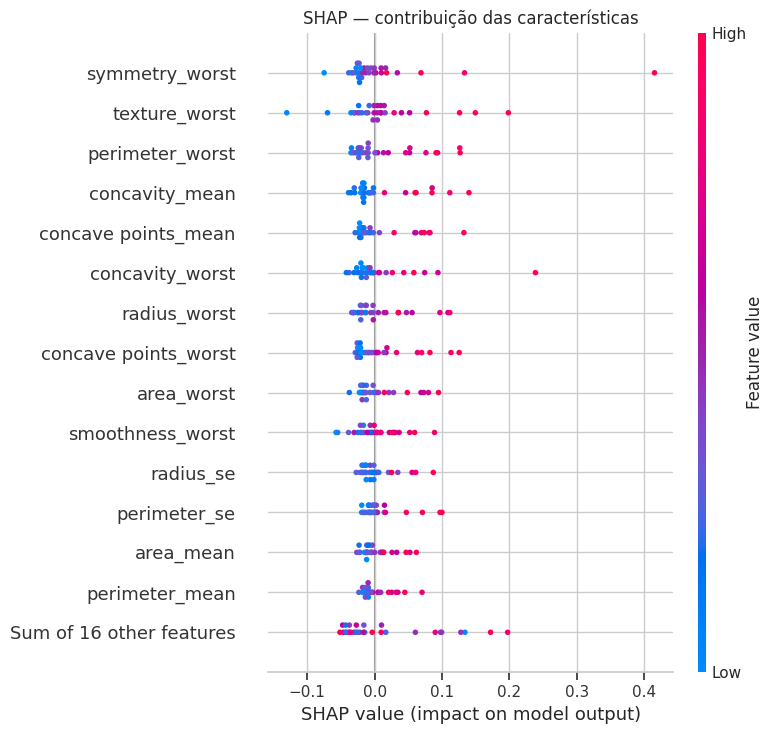

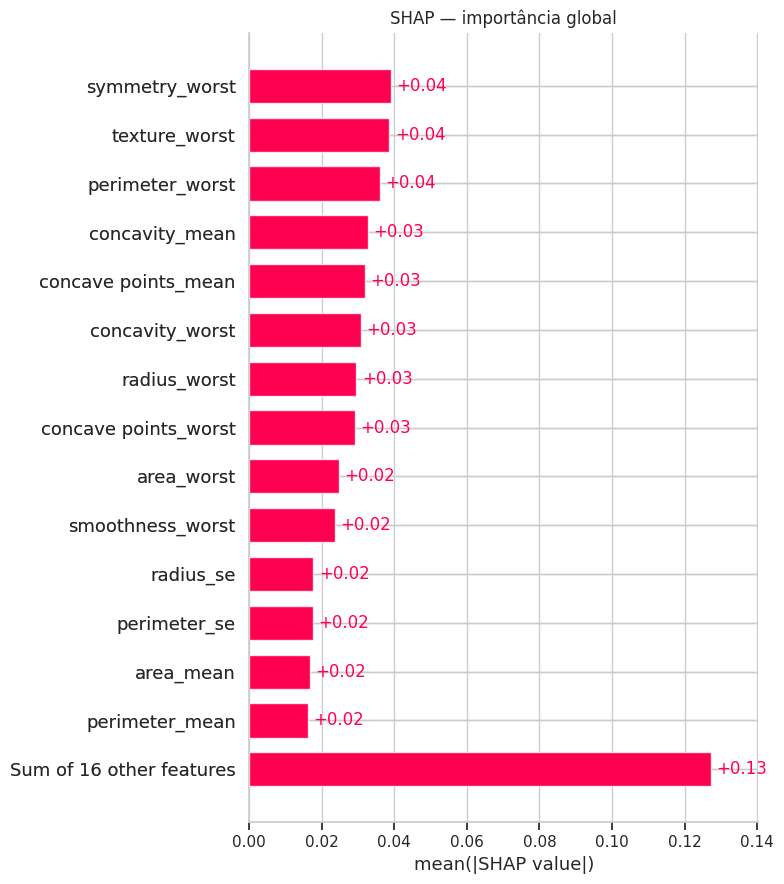

In [14]:
feature_names = list(X.columns)
background = X_train.sample(n=min(30, len(X_train)), random_state=RANDOM_STATE)
examples = X_validation.head(30)


def model_score(values):
    values_frame = pd.DataFrame(values, columns=feature_names)
    return final_model.predict_proba(values_frame)[:, 1]


explainer = shap.Explainer(model_score, background, algorithm="permutation")
shap_values = explainer(examples, max_evals=2 * len(feature_names) + 1)

plt.figure(figsize=(11, 7))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP — contribuição das características")
plt.tight_layout()
plt.savefig(GRAPHICS_DIR / "shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 7))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("SHAP — importância global")
plt.tight_layout()
plt.savefig(GRAPHICS_DIR / "shap_importance.png", dpi=200, bbox_inches="tight")
plt.show()


## Conclusão

O modelo foi escolhido na validação cruzada e a avaliação final foi feita no conjunto de teste reservado. As métricas e gráficos gerados ficam em `results/`. A prioridade de recall maligno pode aumentar falsos positivos e não garante ausência de falsos negativos em outros dados. Os resultados se referem a este exercício e não comprovam segurança para uso clínico.
